## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Membangkitkan Data Sintesis Mahasiswa

Fitur yang dibuat:

| Fitur | Keterangan | Rentang |
|---|---|---|
| `jam_belajar` | Jam belajar mandiri per minggu | 0 - 40 |
| `kehadiran` | Persentase kehadiran kuliah | 40 - 100 |
| `ipk_sebelumnya` | IPK semester sebelumnya | 1.5 - 4.0 |
| `tugas_terkumpul` | Persentase tugas yang dikumpulkan | 30 - 100 |
| `jam_tidur` | Rata-rata jam tidur per hari | 3 - 10 |
| `jam_medsos` | Jam penggunaan media sosial per hari | 0 - 10 |

Target `performa` dibentuk dari skor gabungan fitur ditambah *noise* (agar tidak terlalu sempurna), lalu dibagi menjadi 3 kategori.

In [2]:
N = 600  # jumlah mahasiswa

jam_belajar     = np.clip(np.random.normal(18, 8, N), 0, 40)
kehadiran       = np.clip(np.random.normal(82, 12, N) + 0.2 * (jam_belajar - 18), 40, 100)
ipk_sebelumnya  = np.clip(np.random.normal(3.0, 0.5, N) + 0.01 * (jam_belajar - 18), 1.5, 4.0)
tugas_terkumpul = np.clip(np.random.normal(80, 15, N) + 0.2 * (kehadiran - 82), 30, 100)
jam_tidur       = np.clip(np.random.normal(6.5, 1.2, N), 3, 10)
jam_medsos      = np.clip(np.random.normal(4.5, 2.0, N) - 0.05 * (jam_belajar - 18), 0, 10)

df = pd.DataFrame({
    "jam_belajar": jam_belajar,
    "kehadiran": kehadiran,
    "ipk_sebelumnya": ipk_sebelumnya,
    "tugas_terkumpul": tugas_terkumpul,
    "jam_tidur": jam_tidur,
    "jam_medsos": jam_medsos,
}).round(2)

# Skor performa = kombinasi berbobot fitur (distandarisasi) + noise
z = (df - df.mean()) / df.std()
skor = (0.35 * z["jam_belajar"] + 0.30 * z["kehadiran"] + 0.30 * z["ipk_sebelumnya"]
        + 0.25 * z["tugas_terkumpul"] + 0.10 * z["jam_tidur"] - 0.20 * z["jam_medsos"]
        + np.random.normal(0, 0.45, N))

# Bagi menjadi 3 kategori berdasarkan kuantil (30% Kurang, 40% Cukup, 30% Baik)
df["performa"] = pd.qcut(skor, q=[0, 0.30, 0.70, 1.0], labels=["Kurang", "Cukup", "Baik"])

class_names = ["Kurang", "Cukup", "Baik"]
print("Ukuran data:", df.shape)
df.head(10)

Ukuran data: (600, 7)


,jam_belajar,kehadiran,ipk_sebelumnya,tugas_terkumpul,jam_tidur,jam_medsos,performa
0,21.97,91.88,3.10,100.00,5.63,0.49,Baik
1,16.89,70.71,2.77,76.83,6.71,2.83,Kurang
2,23.18,93.47,3.11,71.67,5.84,3.41,Baik
3,30.18,100.00,3.39,60.89,6.17,7.67,Baik
4,16.13,86.59,3.01,53.87,8.51,5.71,Cukup
5,16.13,100.00,3.00,59.84,8.11,1.92,Cukup
6,30.63,75.24,2.78,82.66,4.94,4.84,Cukup
7,24.14,68.29,2.73,84.89,7.50,1.10,Baik
8,14.24,59.90,2.26,51.86,7.47,6.85,Kurang
9,22.34,100.00,3.92,97.03,5.12,3.34,Baik


In [3]:
# (Opsional) simpan data sintesis ke CSV
df.to_csv("data_mahasiswa_sintesis.csv", index=False)
print("Tersimpan: data_mahasiswa_sintesis.csv (cek di panel file Colab sebelah kiri)")

Tersimpan: data_mahasiswa_sintesis.csv (cek di panel file Colab sebelah kiri)


## 3. Eksplorasi Data (EDA)

In [4]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   jam_belajar      600 non-null    float64 
 1   kehadiran        600 non-null    float64 
 2   ipk_sebelumnya   600 non-null    float64 
 3   tugas_terkumpul  600 non-null    float64 
 4   jam_tidur        600 non-null    float64 
 5   jam_medsos       600 non-null    float64 
 6   performa         600 non-null    category
dtypes: category(1), float64(6)
memory usage: 29.0 KB

Missing values:
 jam_belajar        0
kehadiran          0
ipk_sebelumnya     0
tugas_terkumpul    0
jam_tidur          0
jam_medsos         0
performa           0
dtype: int64


,jam_belajar,kehadiran,ipk_sebelumnya,tugas_terkumpul,jam_tidur,jam_medsos
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,17.89,82.63,3.03,79.29,6.54,4.52
std,7.65,11.27,0.49,13.74,1.18,2.11
min,0.00,47.87,1.52,33.49,3.00,0.00
25%,12.44,75.46,2.69,70.32,5.75,3.02
50%,18.06,82.81,3.02,79.88,6.51,4.58
75%,22.98,91.14,3.36,89.95,7.31,6.04
max,40.00,100.00,4.00,100.00,10.00,10.00


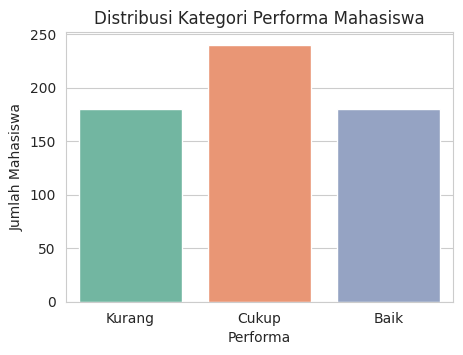

In [5]:
# Distribusi kelas
plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="performa", order=class_names, palette="Set2")
plt.title("Distribusi Kategori Performa Mahasiswa")
plt.xlabel("Performa")
plt.ylabel("Jumlah Mahasiswa")
plt.show()

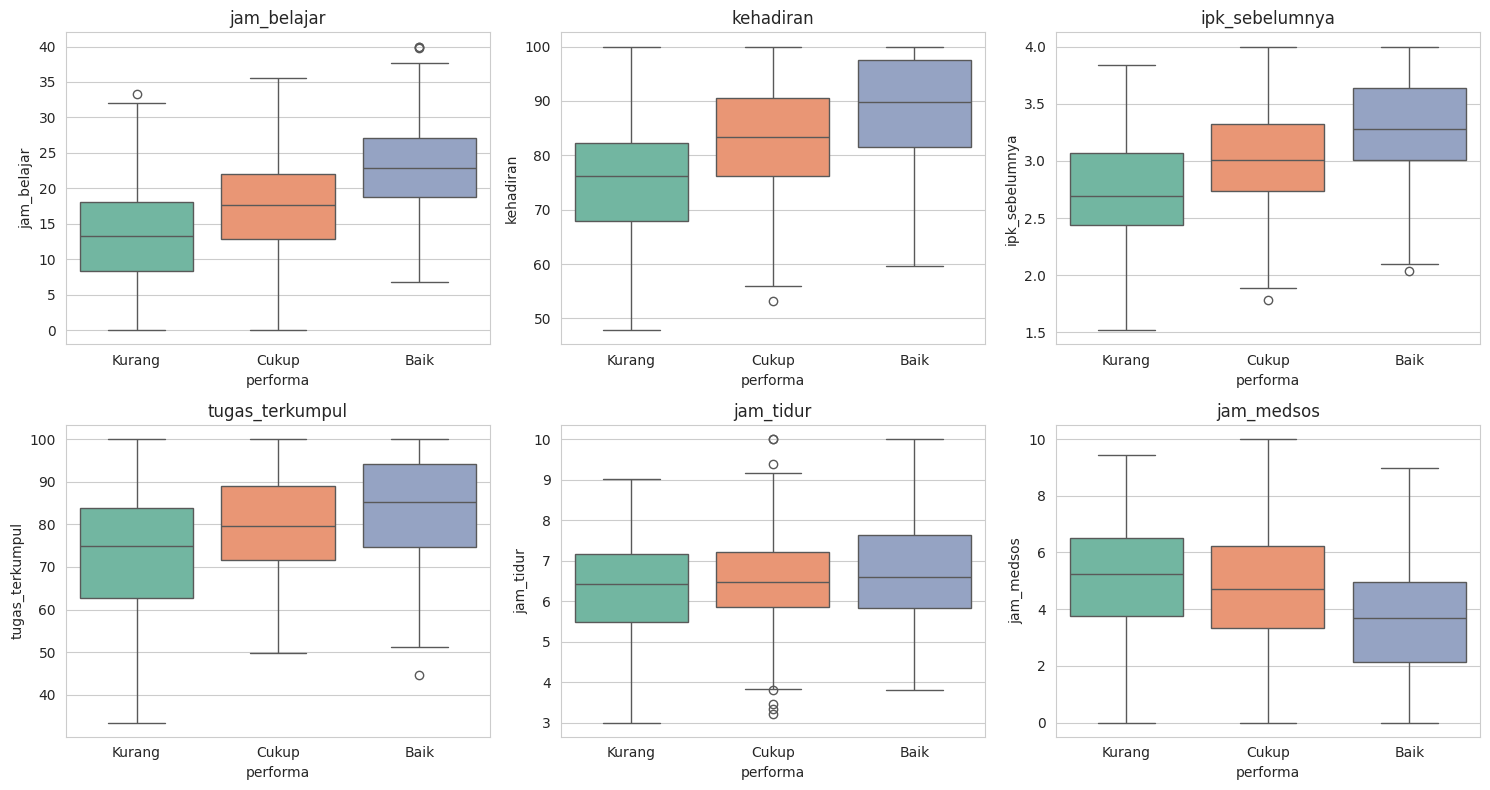

In [6]:
# Distribusi tiap fitur berdasarkan kategori performa
fitur = ["jam_belajar", "kehadiran", "ipk_sebelumnya", "tugas_terkumpul", "jam_tidur", "jam_medsos"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(data=df, x="performa", y=f, order=class_names, palette="Set2", ax=ax)
    ax.set_title(f)
plt.tight_layout()
plt.show()

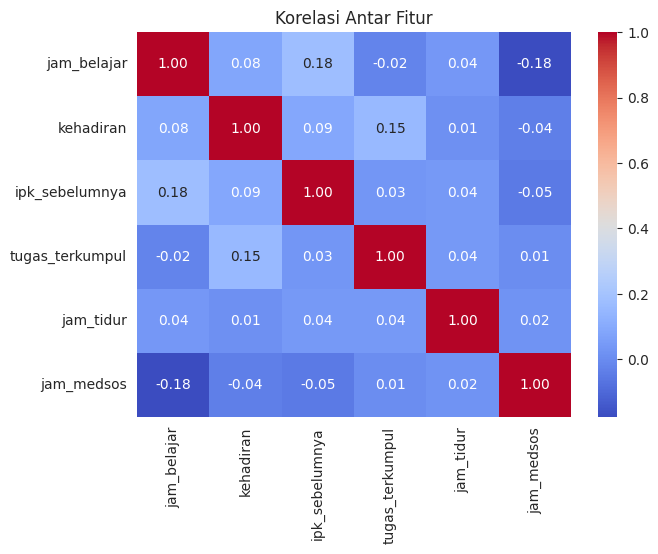

In [7]:
# Korelasi antar fitur
plt.figure(figsize=(7, 5))
sns.heatmap(df[fitur].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi Antar Fitur")
plt.show()

## 4. Persiapan Data

- Data dibagi **80% training** dan **20% testing** (stratified, agar proporsi kelas terjaga).
- **KNN** berbasis jarak sehingga **wajib di-scaling**.
- **Naive Bayes Gaussian** tidak memerlukan scaling, sehingga memakai data asli.

In [8]:
X = df[fitur]
y = df["performa"].map({"Kurang": 0, "Cukup": 1, "Baik": 2})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

Data training: (480, 6)
Data testing : (120, 6)


## 5. Model KNN

### 5.1 Mencari nilai K terbaik (Cross-Validation)

K terbaik: 28 (akurasi CV = 0.6771)


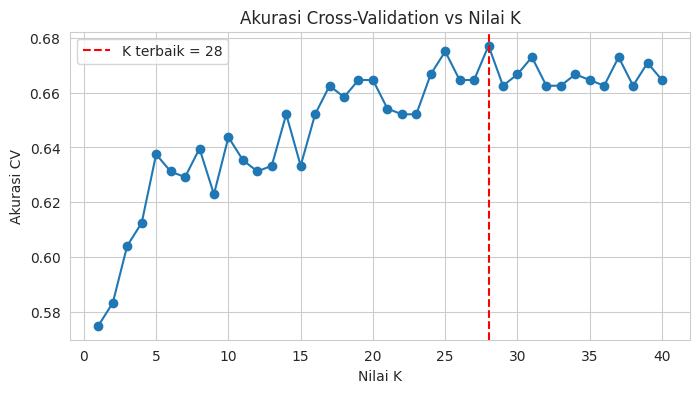

In [9]:
k_range = range(1, 41)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = []
for k in k_range:
    knn_tmp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_tmp, X_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

best_k = k_range[int(np.argmax(cv_scores))]
print(f"K terbaik: {best_k} (akurasi CV = {max(cv_scores):.4f})")

plt.figure(figsize=(8, 4))
plt.plot(k_range, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"K terbaik = {best_k}")
plt.title("Akurasi Cross-Validation vs Nilai K")
plt.xlabel("Nilai K")
plt.ylabel("Akurasi CV")
plt.legend()
plt.show()

### 5.2 Training dan evaluasi KNN

Akurasi KNN (K=28): 0.6750

              precision    recall  f1-score   support

      Kurang       0.65      0.61      0.63        36
       Cukup       0.58      0.73      0.65        48
        Baik       0.92      0.67      0.77        36

    accuracy                           0.68       120
   macro avg       0.72      0.67      0.68       120
weighted avg       0.70      0.68      0.68       120



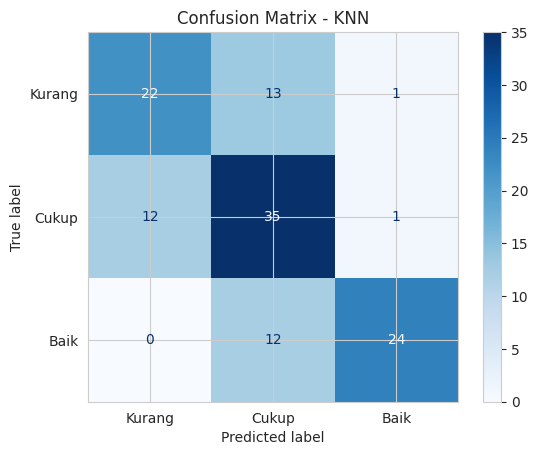

In [10]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"Akurasi KNN (K={best_k}): {acc_knn:.4f}\n")
print(classification_report(y_test, y_pred_knn, target_names=class_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn),
                       display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion Matrix - KNN")
plt.show()

## 6. Model Naive Bayes (Gaussian)

Akurasi Naive Bayes: 0.7167

              precision    recall  f1-score   support

      Kurang       0.71      0.69      0.70        36
       Cukup       0.64      0.67      0.65        48
        Baik       0.83      0.81      0.82        36

    accuracy                           0.72       120
   macro avg       0.73      0.72      0.72       120
weighted avg       0.72      0.72      0.72       120



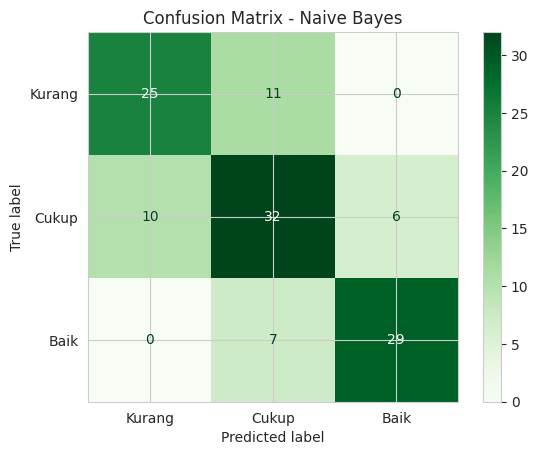

In [11]:
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Akurasi Naive Bayes: {acc_nb:.4f}\n")
print(classification_report(y_test, y_pred_nb, target_names=class_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_nb),
                       display_labels=class_names).plot(cmap="Greens")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

## 7. Perbandingan Model

,Akurasi,Precision (macro),Recall (macro),F1 (macro),Akurasi CV (5-fold)
KNN,0.6750,0.7178,0.6690,0.6836,0.6617
Naive Bayes,0.7167,0.7276,0.7222,0.7247,0.6933


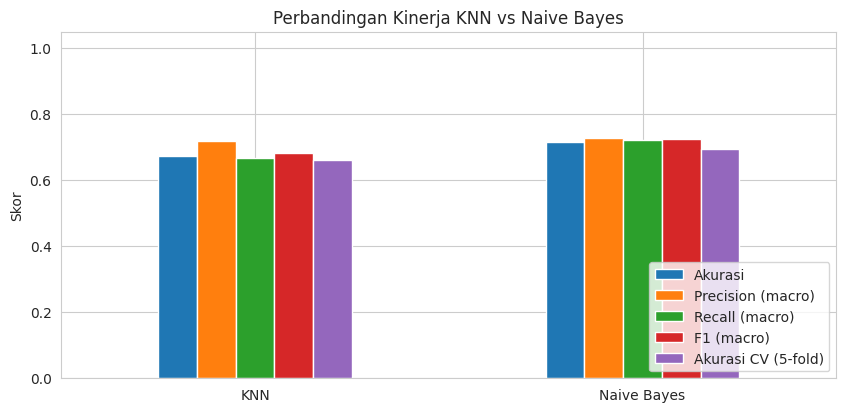

In [12]:
# Pipeline agar scaling dilakukan di dalam tiap fold (menghindari data leakage)
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
nb_pipe = GaussianNB()

cv_knn = cross_val_score(knn_pipe, X, y, cv=cv, scoring="accuracy")
cv_nb = cross_val_score(nb_pipe, X, y, cv=cv, scoring="accuracy")

def metrik(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, average="macro"),
            recall_score(y_true, y_pred, average="macro"),
            f1_score(y_true, y_pred, average="macro")]

hasil = pd.DataFrame(
    [metrik(y_test, y_pred_knn), metrik(y_test, y_pred_nb)],
    columns=["Akurasi", "Precision (macro)", "Recall (macro)", "F1 (macro)"],
    index=["KNN", "Naive Bayes"]
)
hasil["Akurasi CV (5-fold)"] = [cv_knn.mean(), cv_nb.mean()]
hasil = hasil.round(4)
display(hasil)

hasil.plot(kind="bar", figsize=(10, 4.5), rot=0)
plt.title("Perbandingan Kinerja KNN vs Naive Bayes")
plt.ylabel("Skor")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

## 8. Visualisasi Decision Boundary (PCA 2D)

Variansi dijelaskan PC1+PC2: 0.416


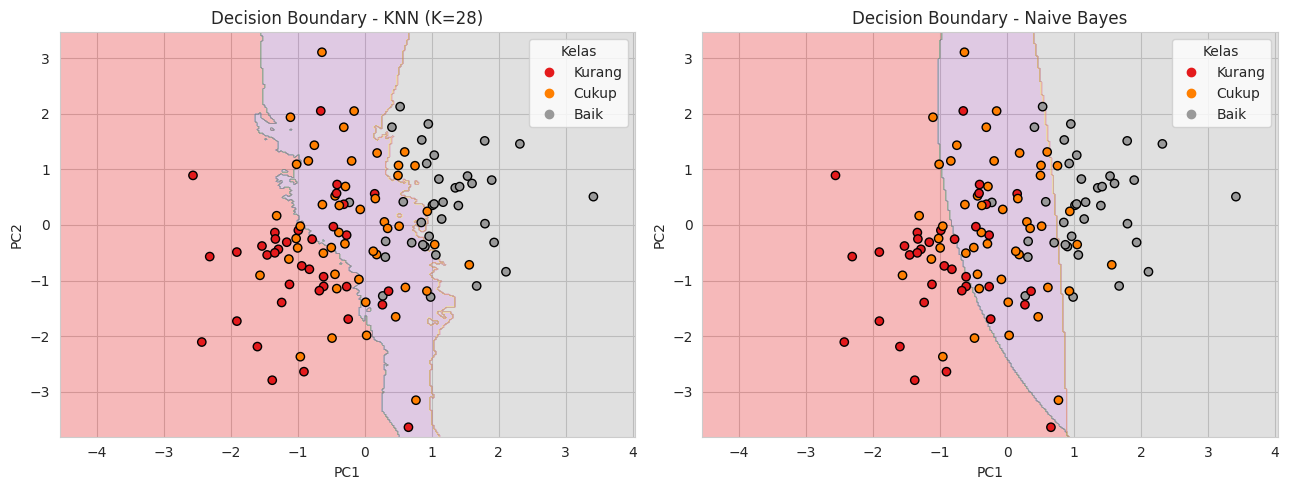

In [13]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Variansi dijelaskan PC1+PC2:", pca.explained_variance_ratio_.sum().round(3))

knn_2d = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_pca, y_train)
nb_2d = GaussianNB().fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model, title in zip(axes, [knn_2d, nb_2d], [f"KNN (K={best_k})", "Naive Bayes"]):
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set1")
    sc = ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap="Set1", edgecolor="k")
    ax.set_title(f"Decision Boundary - {title}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(handles=sc.legend_elements()[0], labels=class_names, title="Kelas")
plt.tight_layout()
plt.show()

## 9. Prediksi Mahasiswa Baru

In [14]:
# Ubah nilai di bawah untuk mencoba mahasiswa lain
mahasiswa_baru = pd.DataFrame([{
    "jam_belajar": 25,
    "kehadiran": 90,
    "ipk_sebelumnya": 3.4,
    "tugas_terkumpul": 95,
    "jam_tidur": 7,
    "jam_medsos": 3,
}])[fitur]

pred_knn = knn.predict(scaler.transform(mahasiswa_baru))[0]
pred_nb = nb.predict(mahasiswa_baru)[0]

print(mahasiswa_baru.to_string(index=False))
print(f"\nPrediksi KNN         : {class_names[pred_knn]}")
print(f"Prediksi Naive Bayes : {class_names[pred_nb]}")
print("\nProbabilitas Naive Bayes:")
for nama, p in zip(class_names, nb.predict_proba(mahasiswa_baru)[0]):
    print(f"  {nama:7s}: {p:.2%}")

 jam_belajar  kehadiran  ipk_sebelumnya  tugas_terkumpul  jam_tidur  jam_medsos
          25         90             3.4               95          7           3

Prediksi KNN         : Baik
Prediksi Naive Bayes : Baik

Probabilitas Naive Bayes:
  Kurang : 0.60%
  Cukup  : 17.45%
  Baik   : 81.95%
